<a href="https://colab.research.google.com/github/Maryam-Shile/Intuitive_pythonista_projects/blob/main/zindi_financial_inclusion_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
train_url = 'https://raw.githubusercontent.com/Maryam-Shile/Intuitive_pythonista_projects/refs/heads/main/Train.csv'
test_url = 'https://raw.githubusercontent.com/Maryam-Shile/Intuitive_pythonista_projects/refs/heads/main/Test.csv'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt,
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier

from sklearn.metrics import mean_absolute_error as mae
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
train_df = pd.read_csv(train_url)
test = pd.read_csv(test_url)

train_df

,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed
...,...,...,...,...,...,...,...,...,...,...,...,...,...
23519,Uganda,2018,uniqueid_2113,No,Rural,Yes,4,48,Female,Head of Household,Divorced/Seperated,No formal education,Other Income
23520,Uganda,2018,uniqueid_2114,No,Rural,Yes,2,27,Female,Head of Household,Single/Never Married,Secondary education,Other Income
23521,Uganda,2018,uniqueid_2115,No,Rural,Yes,5,27,Female,Parent,Widowed,Primary education,Other Income
23522,Uganda,2018,uniqueid_2116,No,Urban,Yes,7,30,Female,Parent,Divorced/Seperated,Secondary education,Self employed


In [ ]:
test['unique_x_country'] = test['uniqueid'] + '_' + test['country']

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   country                 23524 non-null  object
 1   year                    23524 non-null  int64 
 2   uniqueid                23524 non-null  object
 3   bank_account            23524 non-null  object
 4   location_type           23524 non-null  object
 5   cellphone_access        23524 non-null  object
 6   household_size          23524 non-null  int64 
 7   age_of_respondent       23524 non-null  int64 
 8   gender_of_respondent    23524 non-null  object
 9   relationship_with_head  23524 non-null  object
 10  marital_status          23524 non-null  object
 11  education_level         23524 non-null  object
 12  job_type                23524 non-null  object
dtypes: int64(3), object(10)
memory usage: 2.3+ MB


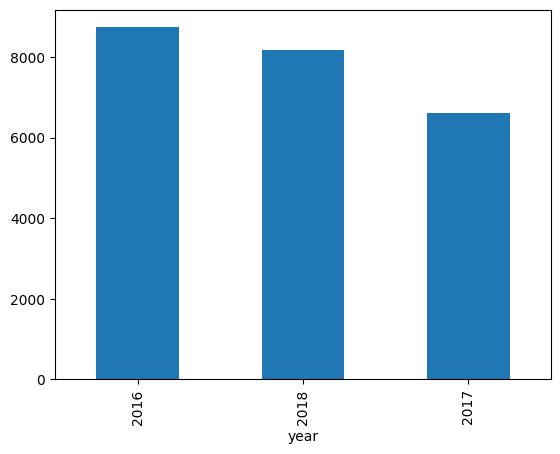

In [ ]:
train_df['year'].value_counts().plot(kind = 'bar')
plt.show()

In [ ]:
train_df[['household_size', 'age_of_respondent', 'year']].describe()

,household_size,age_of_respondent,year
count,23524.000000,23524.000000,23524.000000
mean,3.797483,38.805220,2016.975939
std,2.227613,16.520569,0.847371
min,1.000000,16.000000,2016.000000
25%,2.000000,26.000000,2016.000000
50%,3.000000,35.000000,2017.000000
75%,5.000000,49.000000,2018.000000
max,21.000000,100.000000,2018.000000


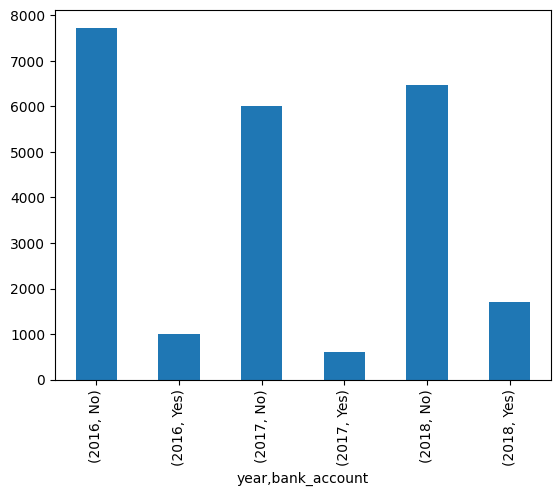

In [ ]:
train_df.groupby('year')['bank_account'].value_counts().plot(kind = 'bar')
plt.show()

In [ ]:
X=train_df.drop(columns =['bank_account', 'uniqueid'], axis = 1).copy()
y = train_df['bank_account'].copy()

y = y.map({'Yes':1, 'No':0})
y = pd.DataFrame(y)

X_train = X[X['year'] < 2018].copy()
X_test = X[X['year'] == 2018].copy()

y_train = y[y.index.isin(X_train.index)].copy()
y_test = y[y.index.isin(X_test.index)].copy()

In [ ]:
cat_cols = list(X.select_dtypes(exclude = 'number').columns)
num_cols = list(X.select_dtypes(include = 'number').columns)

transformer = ColumnTransformer(
    transformers = [
        ('cat', OneHotEncoder(handle_unknown='ignore', drop = 'first'), cat_cols),
        ('num', StandardScaler(), num_cols)
    ]
)

estimators = [
    ('log_reg', LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)),
    ('rf', RandomForestClassifier(random_state=42, class_weight='balanced'))
]

# 2. Build the ensemble
ensemble_voting = VotingClassifier(estimators=estimators, voting='soft')

pipeline = Pipeline(
    steps = [
        ('transformer', transformer),
        ('model', ensemble_voting)
    ]
)

pipeline.fit(X_train, y_train.values.ravel())
y_test['predict'] = pipeline.predict(X_test)

y_test

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,bank_account,predict
0,1,0
1,0,0
2,1,1
3,0,0
4,0,0
...,...,...
23519,0,0
23520,0,0
23521,0,0
23522,0,0


In [ ]:
mae(y_test['bank_account'], y_test['predict'])

0.2149589913086057

In [ ]:
classification_report(y_test['bank_account'], y_test['predict'])

'              precision    recall  f1-score   support\n\n           0       0.89      0.83      0.86      6467\n           1       0.49      0.63      0.55      1702\n\n    accuracy                           0.79      8169\n   macro avg       0.69      0.73      0.70      8169\nweighted avg       0.81      0.79      0.79      8169\n'

,bank_account
0,1
1,0
2,1
3,0
4,0
...,...
23520,0
23521,0
23522,0
23523,0


In [ ]:
test_df = test.drop(columns=['uniqueid', 'unique_x_country'], axis=1).copy()

predicted = pipeline.predict(test_df)

final_df = pd.DataFrame({'uniqueid':test['unique_x_country'], 'bank_account':predicted})

final_df

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,uniqueid,bank_account
0,uniqueid_6056_Kenya,1
1,uniqueid_6060_Kenya,1
2,uniqueid_6065_Kenya,0
3,uniqueid_6072_Kenya,0
4,uniqueid_6073_Kenya,0
...,...,...
10081,uniqueid_2998_Uganda,0
10082,uniqueid_2999_Uganda,0
10083,uniqueid_3000_Uganda,1
10084,uniqueid_3001_Uganda,0


In [ ]:
final_df.to_csv('submission.csv', index=False)